# Unidad I — Dimensión **Viento** en Juliaca (S1–S4) · Nayder Arce Mayta

**Proyecto Sello:** ClimateRisk Andes — riesgo climático para el agro del Altiplano.
**Fuente:** API Open-Meteo (*Historical Weather*, reanálisis ERA5), Juliaca (-15.50082, -70.13980), datos horarios desde 2010.

**Preguntas de negocio de mi dimensión**
1. ¿En qué meses y a qué horas sopla más fuerte el viento en Juliaca, y desde qué dirección?
2. ¿Qué tan probable es un día de ráfaga fuerte en cada mes?
3. ¿Se puede estimar la **ráfaga máxima de hoy** con lo que pasó ayer + la estacionalidad? (regresión MLlib)

> Cambio frente a la U1 anterior (precipitación): la lluvia en época seca vale 0 casi todo el tiempo y en vivo no daba señal; el viento cambia siempre y la misma API lo da en tiempo real (`current=wind_speed_10m`) → sirve para la U2.

## S1 · Arquitectura: **Lambda**

```
                 ┌──────────── CAPA BATCH (U1, este notebook) ─────────────┐
 Open-Meteo      │ CSV horario → Bronze → Silver (diario) → Gold Parquet    │
 archive API ───►│ particionado por anio → modelo MLlib (ráfaga de mañana)  │──┐
                 └──────────────────────────────────────────────────────────┘  │   Grafana
                 ┌──────────── CAPA SPEED (U2, S6–S11) ─────────────────────┐  ├─► (vista de
 Open-Meteo      │ current cada 15 min → MQTT → Kafka viento-eventos →      │  │   servicio)
 forecast API ──►│ Spark Structured Streaming (ventanas, watermark) →       │──┘
                 │ predicción 1 h en vivo → Pushgateway/Prometheus          │
                 └──────────────────────────────────────────────────────────┘
```

**¿Por qué Lambda y no Kappa?**
- Tengo **16 años de histórico** que hay que recalcular completo cuando cambia una regla (umbral, limpieza): eso es batch puro.
- Lo que vuelve el histórico útil (climatología, umbral de alerta, modelo entrenado) se **reutiliza** en la capa speed: el umbral p90 calculado aquí es el que usa el alertador en vivo, y el modelo se aplica al stream.
- Con Kappa tendría que reprocesar 146 mil eventos por Kafka cada vez que cambie la lógica; con Lambda el batch lo hace en segundos con Spark sobre Parquet.
- Costo: la dimensión viento en vivo genera pocos eventos (3 puntos × 1/min), no justifica mantener todo en un log reprocesable.

In [1]:
import os, time, csv, json
from datetime import date, timedelta
import requests

BASE = os.getenv("VIENTO_BASE", "/opt")          # en el contenedor del curso ./sesiones se monta en /opt
DATA = f"{BASE}/data"
ART = f"{BASE}/artifacts"
CSV_HORARIO = f"{DATA}/viento_juliaca_horario.csv"
os.makedirs(DATA, exist_ok=True); os.makedirs(f"{ART}/figs", exist_ok=True)

LAT, LON = -15.50082, -70.13980
ANIO_INICIO = 2010
FECHA_FIN = date.today() - timedelta(days=7)      # el archivo ERA5 llega con ~5 días de atraso
VARIABLES = ("temperature_2m,relative_humidity_2m,surface_pressure,cloud_cover,"
             "wind_speed_10m,wind_direction_10m,wind_gusts_10m")
COLUMNAS = ["fecha_hora", "temperatura", "humedad", "presion", "nubosidad", "velocidad", "direccion", "rafaga"]
print("Rango a descargar:", ANIO_INICIO, "→", FECHA_FIN)

Rango a descargar: 2010 → 2026-10-27


### 1.1 Extracción desde la API (una petición por año, se omite si el CSV ya existe)

In [2]:
def descargar_anio(anio):
    ini = date(anio, 1, 1)
    fin = min(date(anio, 12, 31), FECHA_FIN)
    params = {"latitude": LAT, "longitude": LON, "start_date": ini.isoformat(), "end_date": fin.isoformat(),
              "hourly": VARIABLES, "wind_speed_unit": "kmh", "timezone": "America/Lima"}
    for intento in range(6):
        try:
            r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=180)
            if r.status_code == 429:                       # límite de la API gratuita
                raise RuntimeError("429 demasiadas peticiones")
            r.raise_for_status()
            h = r.json()["hourly"]
            claves = ["time"] + VARIABLES.split(",")
            return list(zip(*[h[k] for k in claves]))
        except Exception as ex:                            # timeout, 429, 5xx → esperar y reintentar
            espera = 20 * (intento + 1)
            print(f"  {anio}: intento {intento + 1} falló ({type(ex).__name__}), reintento en {espera} s")
            time.sleep(espera)
    raise RuntimeError(f"No se pudo descargar {anio}: vuelve a correr la celda, retoma donde quedó")

# Cada año se guarda aparte → si se corta, al volver a correr solo baja lo que falta
RAW = f"{DATA}/raw"; os.makedirs(RAW, exist_ok=True)
for anio in range(ANIO_INICIO, FECHA_FIN.year + 1):
    parcial = f"{RAW}/viento_{anio}.csv"
    if os.path.exists(parcial) and anio < FECHA_FIN.year:
        print(anio, "ya descargado"); continue
    filas = descargar_anio(anio)
    with open(parcial, "w", newline="") as f:
        w = csv.writer(f); w.writerow(COLUMNAS); w.writerows(filas)
    print(anio, len(filas), "filas")
    time.sleep(2)

# Unir todos los años en el CSV final
total = 0
with open(CSV_HORARIO, "w", newline="") as out:
    w = csv.writer(out); w.writerow(COLUMNAS)
    for anio in range(ANIO_INICIO, FECHA_FIN.year + 1):
        with open(f"{RAW}/viento_{anio}.csv") as f:
            r = csv.reader(f); next(r); filas = list(r)
        w.writerows(filas); total += len(filas)
print("Total:", total, "filas →", CSV_HORARIO)

2010 ya descargado
2011 ya descargado
2012 ya descargado
2013 ya descargado
2014 ya descargado
2015 ya descargado
2016 ya descargado
2017 ya descargado
2018 ya descargado
2019 ya descargado
2020 ya descargado
2021 ya descargado
2022 ya descargado
2023 ya descargado
2024 ya descargado
2025 ya descargado
2026 7200 filas
Total: 147456 filas → /opt/data/viento_juliaca_horario.csv


## S2 · Fundamentos PySpark: esquema explícito, transformaciones y evaluación perezosa

In [3]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, StringType, DoubleType

spark = (SparkSession.builder
         .appName("u1-viento-batch-nayder")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "America/Lima")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| usuario:", os.getenv("USER", os.getenv("HOSTNAME")), "|", time.strftime("%Y-%m-%d %H:%M:%S"))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/03 00:03:41 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | usuario: ff3798991c86 | 2026-11-03 00:03:46


In [4]:
esquema = StructType([
    StructField("fecha_hora", StringType(), False),
    StructField("temperatura", DoubleType(), True),
    StructField("humedad", DoubleType(), True),
    StructField("presion", DoubleType(), True),
    StructField("nubosidad", DoubleType(), True),
    StructField("velocidad", DoubleType(), True),   # km/h a 10 m
    StructField("direccion", DoubleType(), True),   # grados (de dónde viene)
    StructField("rafaga", DoubleType(), True),      # km/h a 10 m
])
bronze = spark.read.csv(CSV_HORARIO, header=True, schema=esquema)
bronze.printSchema()
print("Filas Bronze:", bronze.count())
bronze.show(5)

root
 |-- fecha_hora: string (nullable = true)
 |-- temperatura: double (nullable = true)
 |-- humedad: double (nullable = true)
 |-- presion: double (nullable = true)
 |-- nubosidad: double (nullable = true)
 |-- velocidad: double (nullable = true)
 |-- direccion: double (nullable = true)
 |-- rafaga: double (nullable = true)



Filas Bronze: 147456
+----------------+-----------+-------+-------+---------+---------+---------+------+
|      fecha_hora|temperatura|humedad|presion|nubosidad|velocidad|direccion|rafaga|
+----------------+-----------+-------+-------+---------+---------+---------+------+
|2010-01-01T00:00|        6.8|   84.0|  645.3|     93.0|      4.9|    253.0|   9.0|
|2010-01-01T01:00|        5.5|   91.0|  643.7|     89.0|      6.2|    263.0|  11.2|
|2010-01-01T02:00|        5.5|   83.0|  643.4|     91.0|      6.6|    261.0|  12.6|
|2010-01-01T03:00|        5.1|   83.0|  643.1|     96.0|      6.2|    260.0|  13.0|
|2010-01-01T04:00|        4.9|   83.0|  643.2|     85.0|      5.9|    259.0|  13.0|
+----------------+-----------+-------+-------+---------+---------+---------+------+
only showing top 5 rows


### 2.1 Transformaciones (columnas derivadas, `when`, componentes u/v del viento)

In [5]:
SECTORES = F.array(*[F.lit(s) for s in ["N", "NE", "E", "SE", "S", "SO", "O", "NO"]])

horario = (bronze
    .withColumn("ts", F.to_timestamp("fecha_hora", "yyyy-MM-dd'T'HH:mm"))
    .withColumn("fecha", F.to_date("ts"))
    .withColumn("anio", F.year("ts"))
    .withColumn("mes", F.month("ts"))
    .withColumn("hora", F.hour("ts"))
    .withColumn("sector", F.element_at(SECTORES, (F.floor(((F.col("direccion") + 22.5) % 360) / 45) + 1).cast("int")))
    # componentes vectoriales: promediar ángulos directamente da resultados falsos (350° y 10° ≠ 180°)
    .withColumn("u", -F.col("velocidad") * F.sin(F.radians("direccion")))
    .withColumn("v", -F.col("velocidad") * F.cos(F.radians("direccion")))
    .withColumn("beaufort", F.when(F.col("velocidad") < 12, "calma-flojo")
                             .when(F.col("velocidad") < 29, "moderado")
                             .when(F.col("velocidad") < 50, "fresco-fuerte")
                             .otherwise("temporal"))
)
horario.select("ts", "velocidad", "direccion", "sector", "rafaga", "beaufort").show(5)

+-------------------+---------+---------+------+------+-----------+
|                 ts|velocidad|direccion|sector|rafaga|   beaufort|
+-------------------+---------+---------+------+------+-----------+
|2010-01-01 00:00:00|      4.9|    253.0|     O|   9.0|calma-flojo|
|2010-01-01 01:00:00|      6.2|    263.0|     O|  11.2|calma-flojo|
|2010-01-01 02:00:00|      6.6|    261.0|     O|  12.6|calma-flojo|
|2010-01-01 03:00:00|      6.2|    260.0|     O|  13.0|calma-flojo|
|2010-01-01 04:00:00|      5.9|    259.0|     O|  13.0|calma-flojo|
+-------------------+---------+---------+------+------+-----------+
only showing top 5 rows


### 2.2 Evaluación perezosa: definir transformaciones no ejecuta nada; la acción sí

In [6]:
t0 = time.time()
plan = horario.filter(F.col("rafaga") > 40).groupBy("mes").count()   # transformaciones
t1 = time.time()
resultado = plan.collect()                                            # acción
t2 = time.time()
print(f"Definir transformaciones: {t1 - t0:.4f} s  |  ejecutar la acción collect(): {t2 - t1:.2f} s")

Definir transformaciones: 0.0713 s  |  ejecutar la acción collect(): 1.05 s


### 2.3 Agregación diaria (Silver) con `groupBy` + `agg`

In [7]:
diario = (horario.groupBy("fecha")
    .agg(F.count("*").alias("n_horas"),
         F.round(F.avg("velocidad"), 2).alias("velocidad_media"),
         F.max("velocidad").alias("velocidad_max"),
         F.max("rafaga").alias("rafaga_max"),
         F.round(F.avg("u"), 3).alias("u_media"),
         F.round(F.avg("v"), 3).alias("v_media"),
         F.max("temperatura").alias("temp_max"),
         F.min("temperatura").alias("temp_min"),
         F.round(F.avg("humedad"), 2).alias("humedad_media"),
         F.round(F.avg("presion"), 2).alias("presion_media"),
         F.round(F.avg("nubosidad"), 2).alias("nubosidad_media"))
    .withColumn("amplitud_termica", F.round(F.col("temp_max") - F.col("temp_min"), 2))
    .withColumn("direccion_resultante", F.round((F.degrees(F.atan2(-F.col("u_media"), -F.col("v_media"))) + 360) % 360, 1))
    .withColumn("anio", F.year("fecha"))
    .withColumn("mes", F.month("fecha")))
diario.orderBy("fecha").show(5)

[Stage 8:>                                                          (0 + 2) / 2]

+----------+-------+---------------+-------------+----------+-------+-------+--------+--------+-------------+-------------+---------------+----------------+--------------------+----+---+
|     fecha|n_horas|velocidad_media|velocidad_max|rafaga_max|u_media|v_media|temp_max|temp_min|humedad_media|presion_media|nubosidad_media|amplitud_termica|direccion_resultante|anio|mes|
+----------+-------+---------------+-------------+----------+-------+-------+--------+--------+-------------+-------------+---------------+----------------+--------------------+----+---+
|2010-01-01|     24|           5.95|         11.8|      23.0|  0.617|  0.453|    15.1|     4.5|        65.29|       645.91|          83.96|            10.6|               233.7|2010|  1|
|2010-01-02|     24|           5.93|         11.5|      28.1| -1.697|  0.511|    14.4|     5.6|        75.54|       645.53|          83.46|             8.8|               106.8|2010|  1|
|2010-01-03|     24|           5.15|         12.0|      26.3| -0.

### 2.4 Plan de ejecución (`explain`)
Buscar: poda de columnas en el `FileScan csv` (ReadSchema), `HashAggregate` parcial → `Exchange hashpartitioning(fecha, 8)` → `HashAggregate` final.

In [8]:
diario.explain(True)

== Parsed Logical Plan ==
'Project [unresolvedstarwithcolumns(mes, 'month('fecha), None)]
+- Project [fecha#55, n_horas#109L, velocidad_media#110, velocidad_max#111, rafaga_max#112, u_media#113, v_media#114, temp_max#115, temp_min#116, humedad_media#117, presion_media#118, nubosidad_media#119, amplitud_termica#148, direccion_resultante#149, year(fecha#55) AS anio#150]
   +- Project [fecha#55, n_horas#109L, velocidad_media#110, velocidad_max#111, rafaga_max#112, u_media#113, v_media#114, temp_max#115, temp_min#116, humedad_media#117, presion_media#118, nubosidad_media#119, amplitud_termica#148, round(((DEGREES(ATAN2(-u_media#113, -v_media#114)) + cast(360 as double)) % cast(360 as double)), 1) AS direccion_resultante#149]
      +- Project [fecha#55, n_horas#109L, velocidad_media#110, velocidad_max#111, rafaga_max#112, u_media#113, v_media#114, temp_max#115, temp_min#116, humedad_media#117, presion_media#118, nubosidad_media#119, round((temp_max#115 - temp_min#116), 2) AS amplitud_termic

### 2.5 Lo mismo con RDD (API de bajo nivel): horas con ráfaga ≥ 40 km/h por año

In [9]:
rdd = (bronze.rdd
       .filter(lambda r: r.rafaga is not None and r.rafaga >= 40)
       .map(lambda r: (r.fecha_hora[:4], 1))
       .reduceByKey(lambda a, b: a + b)
       .sortByKey())
print(rdd.collect())

[('2010', 174), ('2011', 98), ('2012', 79), ('2013', 127), ('2014', 63), ('2015', 97), ('2016', 121), ('2017', 338), ('2018', 344), ('2019', 311), ('2020', 381), ('2021', 293), ('2022', 444), ('2023', 253), ('2024', 420), ('2025', 545), ('2026', 489)]


## S3 · Procesamiento y calidad: nulos, duplicados, rangos y particionamiento

In [10]:
nulos = bronze.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in bronze.columns])
nulos.show()

total = bronze.count()
distintos = bronze.select("fecha_hora").distinct().count()
print(f"Filas: {total} | marcas de tiempo distintas: {distintos} | duplicadas: {total - distintos}")

fuera = horario.filter(~F.col("velocidad").between(0, 200) | ~F.col("rafaga").between(0, 250)
                       | ~F.col("direccion").between(0, 360) | ~F.col("humedad").between(0, 100)
                       | ~F.col("presion").between(500, 1100))
print("Filas fuera de rango físico:", fuera.count())

+----------+-----------+-------+-------+---------+---------+---------+------+
|fecha_hora|temperatura|humedad|presion|nubosidad|velocidad|direccion|rafaga|
+----------+-----------+-------+-------+---------+---------+---------+------+
|         0|          0|      0|      0|        0|        0|        0|     0|
+----------+-----------+-------+-------+---------+---------+---------+------+

Filas: 147456 | marcas de tiempo distintas: 147456 | duplicadas: 0
Filas fuera de rango físico: 0


In [11]:
# Limpieza: sin nulos en variables clave, sin duplicados de tiempo, dentro de rango
limpio = (horario.dropna(subset=["velocidad", "rafaga", "direccion", "temperatura", "humedad", "presion"])
          .dropDuplicates(["fecha_hora"])
          .filter(F.col("velocidad").between(0, 200) & F.col("rafaga").between(0, 250)
                  & F.col("direccion").between(0, 360) & F.col("humedad").between(0, 100)
                  & F.col("presion").between(500, 1100)))

silver = (limpio.groupBy("fecha")
    .agg(F.count("*").alias("n_horas"),
         F.round(F.avg("velocidad"), 2).alias("velocidad_media"),
         F.max("velocidad").alias("velocidad_max"),
         F.max("rafaga").alias("rafaga_max"),
         F.round(F.avg("u"), 3).alias("u_media"), F.round(F.avg("v"), 3).alias("v_media"),
         F.max("temperatura").alias("temp_max"), F.min("temperatura").alias("temp_min"),
         F.round(F.avg("humedad"), 2).alias("humedad_media"),
         F.round(F.avg("presion"), 2).alias("presion_media"),
         F.round(F.avg("nubosidad"), 2).alias("nubosidad_media"))
    .filter(F.col("n_horas") == 24)                          # solo días completos
    .withColumn("amplitud_termica", F.round(F.col("temp_max") - F.col("temp_min"), 2))
    .withColumn("direccion_resultante", F.round((F.degrees(F.atan2(-F.col("u_media"), -F.col("v_media"))) + 360) % 360, 1))
    .withColumn("anio", F.year("fecha")).withColumn("mes", F.month("fecha"))
    .withColumn("dia_anio", F.dayofyear("fecha")))

n_dias = silver.count()
assert silver.select("fecha").distinct().count() == n_dias, "Hay fechas duplicadas en Silver"
assert silver.filter(F.col("rafaga_max").isNull()).count() == 0
print("Días completos y válidos (Silver):", n_dias)

Días completos y válidos (Silver): 6144


### 3.1 Umbral de ráfaga fuerte (dato propio, se reutiliza en la U2)

In [12]:
p50, p75, p90 = silver.approxQuantile("rafaga_max", [0.5, 0.75, 0.9], 0.001)
UMBRAL = round(p90)
print(f"Ráfaga máxima diaria  p50={p50:.1f}  p75={p75:.1f}  p90={p90:.1f} km/h")
print(f"UMBRAL de ráfaga fuerte = p90 = {UMBRAL} km/h  → usar UMBRAL_RAFAGA_KMH={UMBRAL} en uso-viento/compose.yml")
json.dump({"umbral_rafaga_kmh": UMBRAL, "p50": p50, "p75": p75, "p90": p90}, open(f"{ART}/umbral_viento.json", "w"))

Ráfaga máxima diaria  p50=32.0  p75=39.2  p90=46.4 km/h
UMBRAL de ráfaga fuerte = p90 = 46 km/h  → usar UMBRAL_RAFAGA_KMH=46 en uso-viento/compose.yml


### 3.2 Gold: features de ayer (lags) + etiqueta, en Parquet particionado por `anio`

In [13]:
w = Window.orderBy("fecha")
gold = (silver
    .withColumn("dia_sin", F.round(F.sin(2 * 3.141592653589793 * F.col("dia_anio") / 365.25), 5))
    .withColumn("dia_cos", F.round(F.cos(2 * 3.141592653589793 * F.col("dia_anio") / 365.25), 5))
    .withColumn("rafaga_max_ayer", F.lag("rafaga_max").over(w))
    .withColumn("velocidad_media_ayer", F.lag("velocidad_media").over(w))
    .withColumn("humedad_media_ayer", F.lag("humedad_media").over(w))
    .withColumn("presion_media_ayer", F.lag("presion_media").over(w))
    .withColumn("amplitud_termica_ayer", F.lag("amplitud_termica").over(w))
    .withColumn("nubosidad_media_ayer", F.lag("nubosidad_media").over(w))
    .withColumn("fecha_ayer", F.lag("fecha").over(w))
    .filter(F.datediff("fecha", "fecha_ayer") == 1)          # el "ayer" debe ser realmente el día anterior
    .withColumn("dia_fuerte", (F.col("rafaga_max") >= UMBRAL).cast("int"))
    .drop("fecha_ayer"))

GOLD = f"{ART}/viento_gold"
gold.write.mode("overwrite").partitionBy("anio").parquet(GOLD)
particiones = sorted(p for p in os.listdir(GOLD) if p.startswith("anio="))
print(len(particiones), "particiones:", particiones)

17 particiones: ['anio=2010', 'anio=2011', 'anio=2012', 'anio=2013', 'anio=2014', 'anio=2015', 'anio=2016', 'anio=2017', 'anio=2018', 'anio=2019', 'anio=2020', 'anio=2021', 'anio=2022', 'anio=2023', 'anio=2024', 'anio=2025', 'anio=2026']


In [14]:
# Lectura de vuelta + verificación de poda de particiones
gold_r = spark.read.parquet(GOLD)
assert gold_r.count() == gold.count(), "La lectura de vuelta no coincide"
gold_r.printSchema()
consulta = gold_r.filter(F.col("anio") == 2024).select("fecha", "rafaga_max")
consulta.explain()        # buscar: PartitionFilters: [isnotnull(anio), (anio = 2024)]
print("Filas 2024:", consulta.count())

root
 |-- fecha: date (nullable = true)
 |-- n_horas: long (nullable = true)
 |-- velocidad_media: double (nullable = true)
 |-- velocidad_max: double (nullable = true)
 |-- rafaga_max: double (nullable = true)
 |-- u_media: double (nullable = true)
 |-- v_media: double (nullable = true)
 |-- temp_max: double (nullable = true)
 |-- temp_min: double (nullable = true)
 |-- humedad_media: double (nullable = true)
 |-- presion_media: double (nullable = true)
 |-- nubosidad_media: double (nullable = true)
 |-- amplitud_termica: double (nullable = true)
 |-- direccion_resultante: double (nullable = true)
 |-- mes: integer (nullable = true)
 |-- dia_anio: integer (nullable = true)
 |-- dia_sin: double (nullable = true)
 |-- dia_cos: double (nullable = true)
 |-- rafaga_max_ayer: double (nullable = true)
 |-- velocidad_media_ayer: double (nullable = true)
 |-- humedad_media_ayer: double (nullable = true)
 |-- presion_media_ayer: double (nullable = true)
 |-- amplitud_termica_ayer: double (null

### 3.3 Funciones ventana y joins (particionado y performance)

| Técnica | Para qué en mi caso | Qué mirar en el plan |
|---|---|---|
| Ventana **con partición** `partitionBy("fecha")` | hora del día en que ocurrió la ráfaga máxima | `Exchange hashpartitioning(fecha)` → cada día se procesa en paralelo |
| Ventana **sin partición** (móvil 7 días) | tendencia de la ráfaga | aviso *No Partition Defined*: todo va a 1 partición → aceptable con 6 mil días, no con millones |
| **Broadcast join** (tabla chica) | climatología mensual (12 filas) → anomalía de cada día | `BroadcastHashJoin`, sin shuffle de la tabla grande |
| **Sort-merge join** vs broadcast | horario (147 mil) × diario (6 mil) | comparar tiempos y planes |

In [15]:
# Ventana CON partición: ¿a qué hora ocurre la ráfaga máxima de cada día?
w_dia = Window.partitionBy("fecha").orderBy(F.desc("rafaga"), F.asc("hora"))
hora_pico = (limpio.withColumn("rk", F.row_number().over(w_dia)).filter("rk = 1")
             .select("fecha", F.col("hora").alias("hora_rafaga_max"), F.col("rafaga").alias("rafaga_max_dia")))
print("Horas en que más veces se da la ráfaga máxima del día:")
hora_pico.groupBy("hora_rafaga_max").count().orderBy(F.desc("count")).show(5)
hora_pico.explain()      # buscar: Exchange hashpartitioning(fecha, 8) → Window [row_number() ... partitionBy fecha]

Horas en que más veces se da la ráfaga máxima del día:


[Stage 100:>                                                        (0 + 2) / 2]

+---------------+-----+
|hora_rafaga_max|count|
+---------------+-----+
|             17| 1095|
|             16|  869|
|             15|  760|
|             18|  750|
|             14|  654|
+---------------+-----+
only showing top 5 rows
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [fecha#1638, hora#1644 AS hora_rafaga_max#1482, rafaga#1634 AS rafaga_max_dia#1483]
   +- Filter (rk#1480 = 1)
      +- Window [row_number() windowspecdefinition(fecha#1638, rafaga#1634 DESC NULLS LAST, hora#1644 ASC NULLS FIRST, specifiedwindowframe(RowFrame, unboundedpreceding$(), currentrow$())) AS rk#1480], [fecha#1638], [rafaga#1634 DESC NULLS LAST, hora#1644 ASC NULLS FIRST]
         +- WindowGroupLimit [fecha#1638], [rafaga#1634 DESC NULLS LAST, hora#1644 ASC NULLS FIRST], row_number(), 1, Final
            +- Sort [fecha#1638 ASC NULLS FIRST, rafaga#1634 DESC NULLS LAST, hora#1644 ASC NULLS FIRST], false, 0
               +- Exchange hashpartitioning(fecha#1638, 8), ENSURE_REQ

In [16]:
# Ventana móvil de 7 días (rowsBetween) — sin partición: Spark junta todo en 1 partición
w7 = Window.orderBy("fecha").rowsBetween(-6, 0)
tendencia = gold_r.withColumn("rafaga_media_7d", F.round(F.avg("rafaga_max").over(w7), 1))
tendencia.select("fecha", "rafaga_max", "rafaga_media_7d").orderBy(F.desc("fecha")).show(7)
print("Particiones del resultado:", tendencia.rdd.getNumPartitions(), "← por eso solo sirve con datos chicos")

+----------+----------+---------------+
|     fecha|rafaga_max|rafaga_media_7d|
+----------+----------+---------------+
|2026-10-27|      43.2|           47.6|
|2026-10-26|      50.8|           47.4|
|2026-10-25|      50.0|           48.8|
|2026-10-24|      37.8|           48.4|
|2026-10-23|      54.7|           49.4|
|2026-10-22|      41.4|           46.9|
|2026-10-21|      55.1|           47.9|
+----------+----------+---------------+
only showing top 7 rows
Particiones del resultado: 1 ← por eso solo sirve con datos chicos


In [17]:
# Broadcast join: climatología mensual (12 filas) × Gold (6 mil días) → anomalía de ráfaga
climatologia = (gold_r.groupBy("mes")
                .agg(F.round(F.avg("rafaga_max"), 2).alias("rafaga_clim_mes"),
                     F.round(F.stddev("rafaga_max"), 2).alias("rafaga_std_mes")))
anomalias = (gold_r.join(F.broadcast(climatologia), on="mes", how="inner")
             .withColumn("anomalia", F.round(F.col("rafaga_max") - F.col("rafaga_clim_mes"), 1))
             .withColumn("z", F.round(F.col("anomalia") / F.col("rafaga_std_mes"), 2)))
print("Días más anómalos (ráfaga muy por encima de lo normal para su mes):")
anomalias.orderBy(F.desc("z")).select("fecha", "mes", "rafaga_max", "rafaga_clim_mes", "anomalia", "z").show(5)
anomalias.explain()      # buscar: BroadcastHashJoin [mes] ... BroadcastExchange

Días más anómalos (ráfaga muy por encima de lo normal para su mes):
+----------+---+----------+---------------+--------+----+
|     fecha|mes|rafaga_max|rafaga_clim_mes|anomalia|   z|
+----------+---+----------+---------------+--------+----+
|2023-01-19|  1|      65.5|          32.18|    33.3|4.83|
|2026-07-31|  7|      74.5|          33.89|    40.6|4.35|
|2026-08-17|  8|      81.7|          38.53|    43.2|4.24|
|2025-06-25|  6|      68.0|          31.54|    36.5|3.95|
|2026-03-20|  3|      51.1|          29.98|    21.1|3.79|
+----------+---+----------+---------------+--------+----+
only showing top 5 rows
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [mes#1290, fecha#1276, n_horas#1277L, velocidad_media#1278, velocidad_max#1279, rafaga_max#1280, u_media#1281, v_media#1282, temp_max#1283, temp_min#1284, humedad_media#1285, presion_media#1286, nubosidad_media#1287, amplitud_termica#1288, direccion_resultante#1289, dia_anio#1291, dia_sin#1292, dia_cos#1293, rafaga_ma

In [18]:
# Performance: mismo join (horario 147 mil × diario 6 mil) con Sort-Merge vs Broadcast
def medir(df, veces=3):
    tiempos = []
    for _ in range(veces):
        t = time.time(); n = df.count(); tiempos.append(time.time() - t)
    return n, round(min(tiempos), 2)

horas = limpio.select("fecha", "hora", "rafaga")
dias = silver.select("fecha", "rafaga_max")

spark.conf.set("spark.sql.autoBroadcastJoinThreshold", -1)          # forzar SortMergeJoin
smj = horas.join(dias, "fecha").filter(F.col("rafaga") == F.col("rafaga_max"))
n1, t1 = medir(smj)
print(f"SortMergeJoin     → {n1} filas en {t1} s");   smj.explain()

spark.conf.set("spark.sql.autoBroadcastJoinThreshold", 10 * 1024 * 1024)   # volver al valor por defecto
bhj = horas.join(F.broadcast(dias), "fecha").filter(F.col("rafaga") == F.col("rafaga_max"))
n2, t2 = medir(bhj)
print(f"BroadcastHashJoin → {n2} filas en {t2} s");  bhj.explain()
print(f"Mismo resultado: {n1 == n2} | con broadcast la tabla horaria NO se reparte por fecha para el join")
print("(los Exchange que quedan en ambos planes vienen del dropDuplicates de la limpieza, no del join)")

SortMergeJoin     → 7075 filas en 0.96 s
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [fecha#2591, hora#2597, rafaga#2587, rafaga_max#403]
   +- SortMergeJoin [knownfloatingpointnormalized(normalizenanandzero(rafaga#2587)), fecha#2591], [knownfloatingpointnormalized(normalizenanandzero(rafaga_max#403)), fecha#2623], Inner
      :- Sort [knownfloatingpointnormalized(normalizenanandzero(rafaga#2587)) ASC NULLS FIRST, fecha#2591 ASC NULLS FIRST], false, 0
      :  +- Exchange hashpartitioning(knownfloatingpointnormalized(normalizenanandzero(rafaga#2587)), fecha#2591, 8), ENSURE_REQUIREMENTS, [plan_id=4715]
      :     +- Project [fecha#2591, hora#2597, rafaga#2587]
      :        +- Filter ((((((isnotnull(velocidad#2583) AND isnotnull(rafaga#2587)) AND isnotnull(direccion#2585)) AND isnotnull(humedad#2577)) AND isnotnull(presion#2579)) AND ((((((velocidad#2583 >= 0.0) AND (velocidad#2583 <= 200.0)) AND ((rafaga#2587 >= 0.0) AND (rafaga#2587 <= 250.0))) AND ((direccio

### 3.4 Elección de formato: Parquet vs ORC vs Avro
- **Parquet** (elegido): columnar, compresión por columna, *predicate pushdown* y poda de particiones; es el estándar de Spark y lo leen BI/ML.
- **ORC**: también columnar y muy parecido; más común en el ecosistema Hive.
- **Avro**: por **filas**, ideal para mensajes/streaming con esquema (Kafka), malo para consultas analíticas que leen pocas columnas. Necesita el paquete externo `spark-avro`, por eso no lo usamos en el batch.

In [19]:
def tam_mb(ruta):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(ruta)
               for f in fs if not f.startswith((".", "_"))) / 1e6

GOLD_ORC = f"{ART}/viento_gold_orc"
gold_r.write.mode("overwrite").partitionBy("anio").orc(GOLD_ORC)
print(f"CSV horario (Bronze): {os.path.getsize(CSV_HORARIO) / 1e6:8.3f} MB")
print(f"Gold Parquet        : {tam_mb(GOLD):8.3f} MB")
print(f"Gold ORC            : {tam_mb(GOLD_ORC):8.3f} MB")
t = time.time(); spark.read.parquet(GOLD).filter("anio = 2024").agg(F.avg("rafaga_max")).collect(); tp = time.time() - t
t = time.time(); spark.read.orc(GOLD_ORC).filter("anio = 2024").agg(F.avg("rafaga_max")).collect(); to = time.time() - t
print(f"Consulta 2024 → Parquet {tp:.2f} s | ORC {to:.2f} s")

CSV horario (Bronze):    6.971 MB
Gold Parquet        :    0.688 MB
Gold ORC            :    0.456 MB
Consulta 2024 → Parquet 1.00 s | ORC 1.06 s


## Respuesta a las preguntas 1 y 2 (climatología del viento)

In [20]:
import matplotlib.pyplot as plt
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

por_mes = (gold_r.groupBy("mes")
           .agg(F.round(F.avg("velocidad_media"), 1).alias("vel_media"),
                F.round(F.avg("rafaga_max"), 1).alias("rafaga_max_media"),
                F.round(100 * F.avg("dia_fuerte"), 1).alias("pct_dias_fuertes"))
           .orderBy("mes"))
por_mes.show(12)

por_hora = (limpio.groupBy("hora").agg(F.round(F.avg("velocidad"), 1).alias("vel_media"),
                                       F.round(F.avg("rafaga"), 1).alias("rafaga_media")).orderBy("hora"))
por_hora.show(24)

sectores = (limpio.filter(F.col("velocidad") >= 5).groupBy("sector").count()
            .withColumn("pct", F.round(100 * F.col("count") / F.sum("count").over(Window.partitionBy()), 1))
            .orderBy(F.desc("count")))
sectores.show()

+---+---------+----------------+----------------+
|mes|vel_media|rafaga_max_media|pct_dias_fuertes|
+---+---------+----------------+----------------+
|  1|      7.1|            32.2|             4.0|
|  2|      7.0|            31.8|             2.7|
|  3|      6.6|            30.0|             0.8|
|  4|      6.6|            28.6|             1.2|
|  5|      7.2|            29.8|             5.5|
|  6|      7.7|            31.5|             9.0|
|  7|      7.8|            33.9|            11.6|
|  8|      8.7|            38.5|            18.6|
|  9|      8.4|            38.3|            22.0|
| 10|      8.4|            37.9|            22.0|
| 11|      8.8|            38.6|            23.5|
| 12|      7.5|            33.9|            10.1|
+---+---------+----------------+----------------+

+----+---------+------------+
|hora|vel_media|rafaga_media|
+----+---------+------------+
|   0|      7.1|        14.6|
|   1|      6.8|        13.8|
|   2|      6.4|        13.1|
|   3|      6.0|   

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


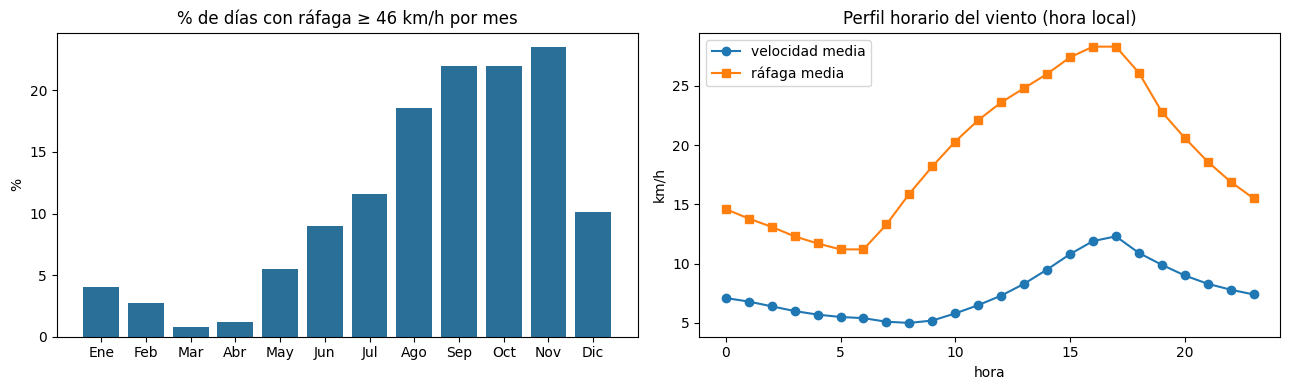

In [21]:
pm, ph = por_mes.toPandas(), por_hora.toPandas()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar([MESES[m - 1] for m in pm.mes], pm.pct_dias_fuertes, color="#2a6f97")
ax[0].set_title(f"% de días con ráfaga ≥ {UMBRAL} km/h por mes"); ax[0].set_ylabel("%")
ax[1].plot(ph.hora, ph.vel_media, marker="o", label="velocidad media")
ax[1].plot(ph.hora, ph.rafaga_media, marker="s", label="ráfaga media")
ax[1].set_title("Perfil horario del viento (hora local)"); ax[1].set_xlabel("hora"); ax[1].set_ylabel("km/h"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{ART}/figs/u1_climatologia_viento.png", dpi=120); plt.show()

## S4 · ML distribuido (regresión): ráfaga máxima de **hoy** con datos de **ayer**

- **Baseline de persistencia:** ráfaga de hoy = ráfaga de ayer (lo que hay que superar).
- **Config A:** solo estacionalidad (`dia_sin`, `dia_cos`) — LinearRegression.
- **Config B:** estacionalidad + condiciones de ayer — LinearRegression.
- **Config C:** mismas features que B — RandomForestRegressor (50 árboles, prof. 8, seed 42).
- División **cronológica** 80/20 (no `randomSplit`: con series de tiempo mezclar futuro y pasado infla las métricas).

In [22]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

FEAT_A = ["dia_sin", "dia_cos"]
FEAT_B = FEAT_A + ["rafaga_max_ayer", "velocidad_media_ayer", "humedad_media_ayer",
                   "presion_media_ayer", "amplitud_termica_ayer", "nubosidad_media_ayer"]

datos = gold_r.select("fecha", "rafaga_max", *FEAT_B).dropna()
ordenado = datos.withColumn("idx", F.row_number().over(Window.orderBy("fecha")))
n = ordenado.count(); corte = int(n * 0.8)
train = ordenado.filter(F.col("idx") <= corte).drop("idx").cache()
test = ordenado.filter(F.col("idx") > corte).drop("idx").cache()
print(f"train={train.count()}  test={test.count()}")
print("train hasta:", train.agg(F.max("fecha")).first()[0], "| test desde:", test.agg(F.min("fecha")).first()[0])

train=4914  test=1229
train hasta: 2023-06-16 | test desde: 2023-06-17


In [23]:
def evaluar(pred, col_pred="prediction"):
    ev = RegressionEvaluator(labelCol="rafaga_max", predictionCol=col_pred)
    return {m: round(ev.setMetricName(m).evaluate(pred), 4) for m in ["rmse", "mae", "r2"]}

resultados = {}
resultados["Baseline persistencia"] = evaluar(test.withColumn("prediction", F.col("rafaga_max_ayer")))

modelos = {
    "A · LR estacional": Pipeline(stages=[VectorAssembler(inputCols=FEAT_A, outputCol="features"),
                                          LinearRegression(featuresCol="features", labelCol="rafaga_max")]),
    "B · LR estacional+ayer": Pipeline(stages=[VectorAssembler(inputCols=FEAT_B, outputCol="features"),
                                               LinearRegression(featuresCol="features", labelCol="rafaga_max")]),
    "C · RF estacional+ayer": Pipeline(stages=[VectorAssembler(inputCols=FEAT_B, outputCol="features"),
                                               RandomForestRegressor(featuresCol="features", labelCol="rafaga_max",
                                                                     numTrees=50, maxDepth=8, seed=42)]),
}
ajustados = {}
for nombre, pipe in modelos.items():
    ajustados[nombre] = pipe.fit(train)
    resultados[nombre] = evaluar(ajustados[nombre].transform(test))

import pandas as pd
tabla = pd.DataFrame(resultados).T
base_rmse = tabla.loc["Baseline persistencia", "rmse"]
tabla["mejora_rmse_vs_baseline_%"] = ((base_rmse - tabla["rmse"]) / base_rmse * 100).round(2)
tabla

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


,rmse,mae,r2,mejora_rmse_vs_baseline_%
Baseline persistencia,9.4461,7.0709,0.0027,0.00
A · LR estacional,10.6093,8.3162,-0.2580,-12.31
B · LR estacional+ayer,9.1538,7.0667,0.0635,3.09
C · RF estacional+ayer,9.4807,7.2985,-0.0046,-0.37


In [24]:
ganador = tabla.drop("Baseline persistencia")["rmse"].idxmin()
print("Ganador:", ganador, "| RMSE", tabla.loc[ganador, "rmse"], "vs baseline", base_rmse)
if tabla.loc[ganador, "rmse"] >= base_rmse:
    print("OJO: ningún modelo supera a la persistencia → se reporta tal cual (hallazgo).")

lr_b = ajustados["B · LR estacional+ayer"].stages[-1]
print("\nCoeficientes Config B (LR):")
for f_, c_ in zip(FEAT_B, lr_b.coefficients):
    print(f"  {f_:24s} {c_:+.4f}")
print(f"  intercepto               {lr_b.intercept:+.4f}")

MODELO = f"{ART}/modelo_rafaga_u1"
ajustados[ganador].write().overwrite().save(MODELO)
recargado = PipelineModel.load(MODELO)
recargado.transform(test).select("fecha", "rafaga_max", F.round("prediction", 1).alias("prediccion")).orderBy(F.desc("fecha")).show(7)
json.dump({"ganador": ganador, "metricas": tabla.to_dict(orient="index")}, open(f"{ART}/metricas_u1.json", "w"), indent=2, default=float)

Ganador: B · LR estacional+ayer | RMSE 9.1538 vs baseline 9.4461

Coeficientes Config B (LR):
  dia_sin                  -1.5086
  dia_cos                  +0.9612
  rafaga_max_ayer          +0.2691
  velocidad_media_ayer     +0.8477
  humedad_media_ayer       -0.0854
  presion_media_ayer       +0.3170
  amplitud_termica_ayer    +0.0601
  nubosidad_media_ayer     +0.0098
  intercepto               -183.9160
+----------+----------+----------+
|     fecha|rafaga_max|prediccion|
+----------+----------+----------+
|2026-10-27|      43.2|      37.3|
|2026-10-26|      50.8|      38.4|
|2026-10-25|      50.0|      33.7|
|2026-10-24|      37.8|      41.4|
|2026-10-23|      54.7|      37.1|
|2026-10-22|      41.4|      42.1|
|2026-10-21|      55.1|      40.3|
+----------+----------+----------+
only showing top 7 rows


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


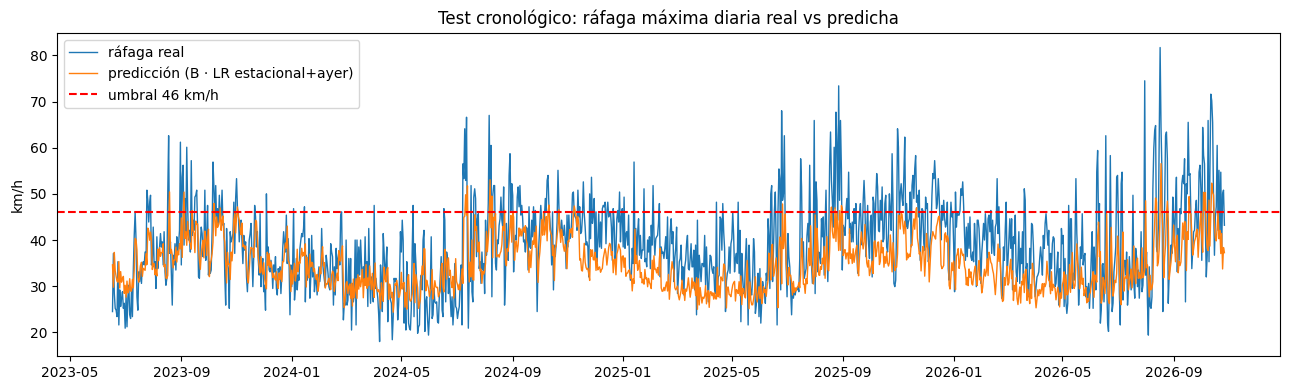

In [25]:
pr = recargado.transform(test).select("fecha", "rafaga_max", "prediction").orderBy("fecha").toPandas()
plt.figure(figsize=(13, 4))
plt.plot(pr.fecha, pr.rafaga_max, label="ráfaga real", lw=1)
plt.plot(pr.fecha, pr.prediction, label=f"predicción ({ganador})", lw=1)
plt.axhline(UMBRAL, color="red", ls="--", label=f"umbral {UMBRAL} km/h")
plt.title("Test cronológico: ráfaga máxima diaria real vs predicha"); plt.ylabel("km/h"); plt.legend()
plt.tight_layout(); plt.savefig(f"{ART}/figs/u1_prediccion_test.png", dpi=120); plt.show()

## S4b · Clasificación complementaria: ¿hoy será un **día de ráfaga fuerte** (≥ umbral p90)?
La alerta de la U2 es una decisión **sí/no**, así que además de la regresión entrenamos clasificadores
con las mismas features (estacionalidad + condiciones de ayer) y el mismo split cronológico.
- Clases desbalanceadas (~10 % de días fuertes) → **pesos de clase** (`weightCol`) para que el modelo no diga siempre "no".
- Baseline: **persistencia** (si ayer fue fuerte, hoy también; puntaje = ráfaga de ayer).
- Métricas: **AUC-ROC**, AUC-PR, precisión, recall, F1, matriz de confusión y **curva ROC**.

In [26]:
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array
import numpy as np

tr_c = train.withColumn("label", (F.col("rafaga_max") >= UMBRAL).cast("double"))
te_c = test.withColumn("label", (F.col("rafaga_max") >= UMBRAL).cast("double"))
p_pos = tr_c.agg(F.avg("label")).first()[0]
tr_c = tr_c.withColumn("peso", F.when(F.col("label") == 1, (1 - p_pos) / p_pos).otherwise(1.0))
print(f"Días fuertes (≥ {UMBRAL} km/h): train {100 * p_pos:.1f} % | test {100 * te_c.agg(F.avg('label')).first()[0]:.1f} %")
print(f"Peso de la clase positiva: {(1 - p_pos) / p_pos:.2f}")

def metricas_clf(pred, score="rawPrediction"):
    ev = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol=score)
    c = pred.agg(F.sum(((F.col("label") == 1) & (F.col("prediction") == 1)).cast("int")).alias("VP"),
                 F.sum(((F.col("label") == 0) & (F.col("prediction") == 1)).cast("int")).alias("FP"),
                 F.sum(((F.col("label") == 1) & (F.col("prediction") == 0)).cast("int")).alias("FN"),
                 F.sum(((F.col("label") == 0) & (F.col("prediction") == 0)).cast("int")).alias("VN")).first()
    prec = c.VP / (c.VP + c.FP) if (c.VP + c.FP) else 0.0
    rec = c.VP / (c.VP + c.FN) if (c.VP + c.FN) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return {"auc_roc": round(ev.setMetricName("areaUnderROC").evaluate(pred), 4),
            "auc_pr": round(ev.setMetricName("areaUnderPR").evaluate(pred), 4),
            "precision": round(prec, 4), "recall": round(rec, 4), "f1": round(f1, 4),
            "VP": c.VP, "FP": c.FP, "FN": c.FN, "VN": c.VN}

res_c = {}
base_c = (te_c.withColumn("prediction", (F.col("rafaga_max_ayer") >= UMBRAL).cast("double"))
               .withColumn("score", F.col("rafaga_max_ayer")))
res_c["Baseline persistencia"] = metricas_clf(base_c, score="score")

clasificadores = {
    "LogReg (pesos)": Pipeline(stages=[VectorAssembler(inputCols=FEAT_B, outputCol="features"),
                                       LogisticRegression(labelCol="label", weightCol="peso", maxIter=100)]),
    "RF clasificador (pesos)": Pipeline(stages=[VectorAssembler(inputCols=FEAT_B, outputCol="features"),
                                                RandomForestClassifier(labelCol="label", weightCol="peso",
                                                                       numTrees=100, maxDepth=6, seed=42)]),
}
ajust_c, pred_c = {}, {}
for nombre, pipe in clasificadores.items():
    ajust_c[nombre] = pipe.fit(tr_c)
    pred_c[nombre] = ajust_c[nombre].transform(te_c).cache()
    res_c[nombre] = metricas_clf(pred_c[nombre])

tabla_c = pd.DataFrame(res_c).T
tabla_c

Días fuertes (≥ 46 km/h): train 8.2 % | test 21.7 %
Peso de la clase positiva: 11.25


,auc_roc,auc_pr,precision,recall,f1,VP,FP,FN,VN
Baseline persistencia,0.7545,0.4672,0.4644,0.4644,0.4644,124.0,143.0,143.0,819.0
LogReg (pesos),0.7745,0.4735,0.4082,0.6742,0.5085,180.0,261.0,87.0,701.0
RF clasificador (pesos),0.7502,0.4284,0.4498,0.5206,0.4826,139.0,170.0,128.0,792.0


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization

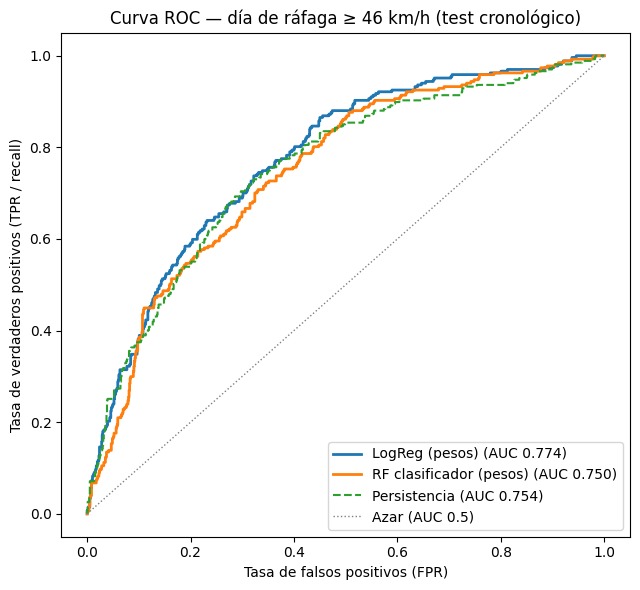

In [27]:
# Curva ROC (FPR vs TPR) calculada sobre las probabilidades del test
def curva_roc(y, s):
    orden = np.argsort(-s); y = y[orden]
    tpr = np.concatenate([[0], np.cumsum(y) / y.sum()])
    fpr = np.concatenate([[0], np.cumsum(1 - y) / (1 - y).sum()])
    return fpr, tpr

plt.figure(figsize=(6.5, 6))
for nombre, pr_ in pred_c.items():
    d = pr_.select("label", vector_to_array("probability")[1].alias("p")).toPandas()
    fpr, tpr = curva_roc(d.label.values, d.p.values)
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC {res_c[nombre]['auc_roc']:.3f})")
d = base_c.select("label", "score").toPandas()
fpr, tpr = curva_roc(d.label.values, d.score.values)
plt.plot(fpr, tpr, lw=1.5, ls="--", label=f"Persistencia (AUC {res_c['Baseline persistencia']['auc_roc']:.3f})")
plt.plot([0, 1], [0, 1], color="gray", lw=1, ls=":", label="Azar (AUC 0.5)")
plt.xlabel("Tasa de falsos positivos (FPR)"); plt.ylabel("Tasa de verdaderos positivos (TPR / recall)")
plt.title(f"Curva ROC — día de ráfaga ≥ {UMBRAL} km/h (test cronológico)"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{ART}/figs/u1_curva_roc.png", dpi=120); plt.show()

In [28]:
ganador_c = tabla_c.drop("Baseline persistencia")["auc_roc"].idxmax()
g = res_c[ganador_c]
print(f"Ganador por AUC-ROC: {ganador_c} | AUC {g['auc_roc']} vs persistencia {res_c['Baseline persistencia']['auc_roc']}")
print(f"\nMatriz de confusión ({ganador_c}, umbral de probabilidad 0.5):")
print(f"                 pred. NO   pred. SÍ")
print(f"real NO (normal)  {g['VN']:7d}   {g['FP']:7d}")
print(f"real SÍ (fuerte)  {g['FN']:7d}   {g['VP']:7d}")
print(f"\nDe cada 10 alertas, {10 * g['precision']:.1f} son correctas (precisión); "
      f"se detectan {100 * g['recall']:.0f} % de los días fuertes (recall).")

MODELO_C = f"{ART}/modelo_dia_fuerte_u1"
ajust_c[ganador_c].write().overwrite().save(MODELO_C)
PipelineModel.load(MODELO_C).transform(te_c).select("fecha", "rafaga_max", "label", "prediction").orderBy(F.desc("fecha")).show(5)
json.dump({"ganador": ganador_c, "umbral_kmh": UMBRAL, "metricas": tabla_c.to_dict(orient="index")},
          open(f"{ART}/metricas_clasificacion_u1.json", "w"), indent=2, default=float)

Ganador por AUC-ROC: LogReg (pesos) | AUC 0.7745 vs persistencia 0.7545

Matriz de confusión (LogReg (pesos), umbral de probabilidad 0.5):
                 pred. NO   pred. SÍ
real NO (normal)      701       261
real SÍ (fuerte)       87       180

De cada 10 alertas, 4.1 son correctas (precisión); se detectan 67 % de los días fuertes (recall).
+----------+----------+-----+----------+
|     fecha|rafaga_max|label|prediction|
+----------+----------+-----+----------+
|2026-10-27|      43.2|  0.0|       0.0|
|2026-10-26|      50.8|  1.0|       1.0|
|2026-10-25|      50.0|  1.0|       0.0|
|2026-10-24|      37.8|  0.0|       1.0|
|2026-10-23|      54.7|  1.0|       0.0|
+----------+----------+-----+----------+
only showing top 5 rows


## Conclusiones (completar con los números de tu corrida)

- **Meses de más viento:** ver tabla `por_mes` (columna `pct_dias_fuertes`).
- **Horas:** el perfil horario muestra el pico de la tarde (calentamiento del Altiplano) — reportar la hora pico.
- **Dirección dominante:** ver tabla `sectores`.
- **Umbral p90** calculado aquí → es el umbral del alertador en vivo (U2).
- **Modelo:** reportar RMSE/MAE/R² del ganador y **cuánto mejora a la persistencia**; si no la supera, decirlo.
- **Limitación honesta:** ERA5 es reanálisis (≈ 25 km de resolución), no un anemómetro en Juliaca; suaviza ráfagas locales.

In [29]:
spark.stop()